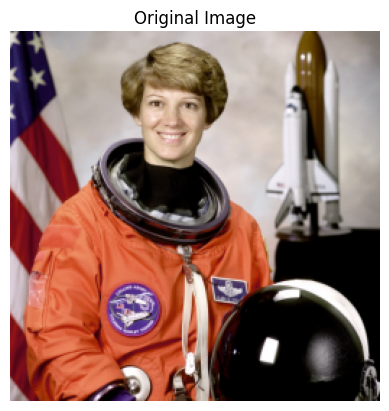

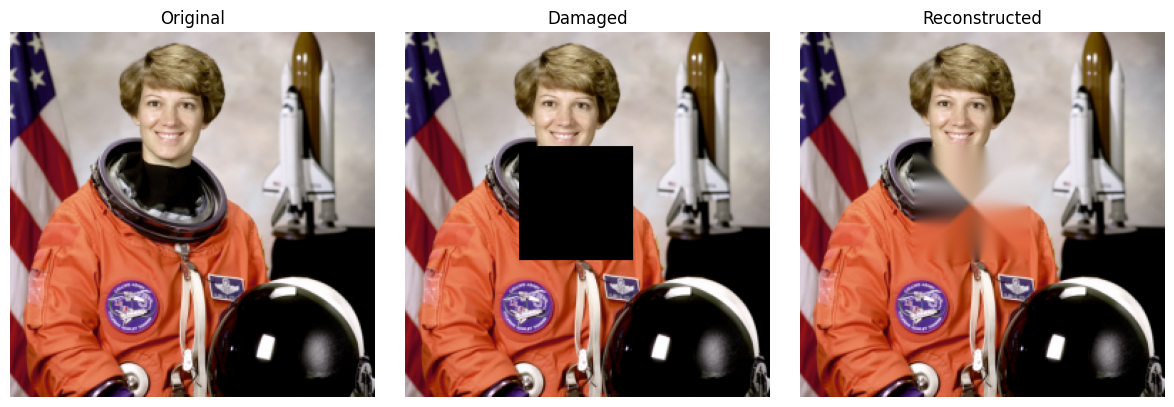

In [ ]:
%pip -q install opencv-python-headless matplotlib scikit-image

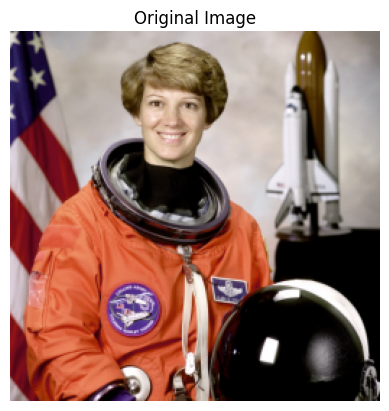

In [ ]:

import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

# Load an example photograph
original = data.astronaut()

# Resize to 256 x 256 pixels
original = resize(
    original,
    (256, 256),
    preserve_range=True,
    anti_aliasing=True
).astype(np.uint8)

plt.imshow(original)
plt.title("Original Image")
plt.axis("off")
plt.show()


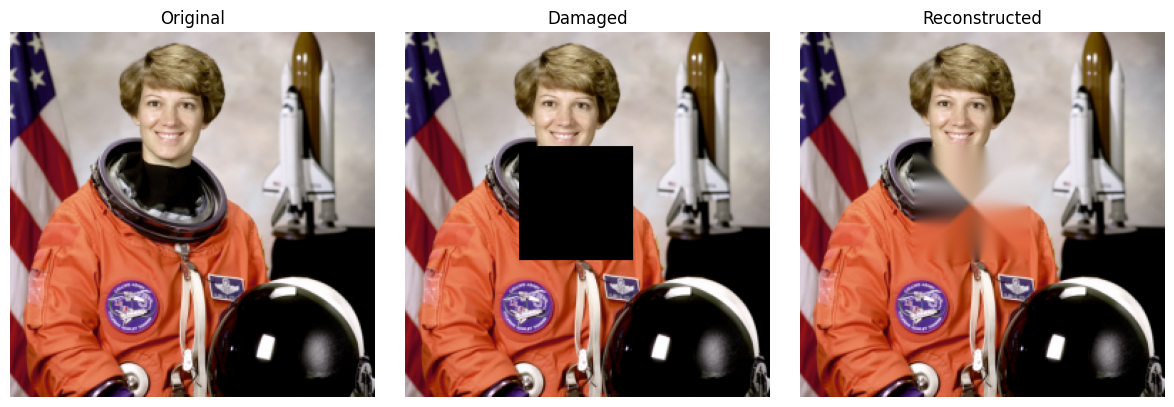

In [ ]:

# Create a binary mask
mask = np.zeros((256, 256), dtype=np.uint8)

# Define the missing region
mask[80:160, 80:160] = 255

# Remove the selected pixels
damaged = original.copy()
damaged[mask == 255] = 0

# OpenCV expects BGR images
damaged_bgr = cv2.cvtColor(
    damaged, cv2.COLOR_RGB2BGR
)

# Reconstruct missing pixels
restored_bgr = cv2.inpaint(
    damaged_bgr,
    mask,
    inpaintRadius=3,
    flags=cv2.INPAINT_TELEA
)

# Convert back to RGB
restored = cv2.cvtColor(
    restored_bgr, cv2.COLOR_BGR2RGB
)

# Show the experiment
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

images = [original, damaged, restored]
titles = ["Original", "Damaged", "Reconstructed"]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Compare only pixels inside the missing area
missing = mask > 0

# Calculate Mean Absolute Error (MAE)
error = np.abs(
    original.astype(np.float32) -
    restored.astype(np.float32)
)

masked_mae = error[missing].mean()

# Calculate masked Mean Squared Error (MSE)
masked_mse = np.mean(
    (original.astype(np.float32)[missing] -
     restored.astype(np.float32)[missing]) ** 2
)

# Calculate masked PSNR
if masked_mse == 0:
    masked_psnr = float("inf")
else:
    masked_psnr = 10 * np.log10(
        (255.0 ** 2) / masked_mse
    )

print(f"Masked MAE: {masked_mae:.2f}")
print(f"Masked PSNR: {masked_psnr:.2f} dB")


Masked MAE: 68.63
Masked PSNR: 8.64 dB


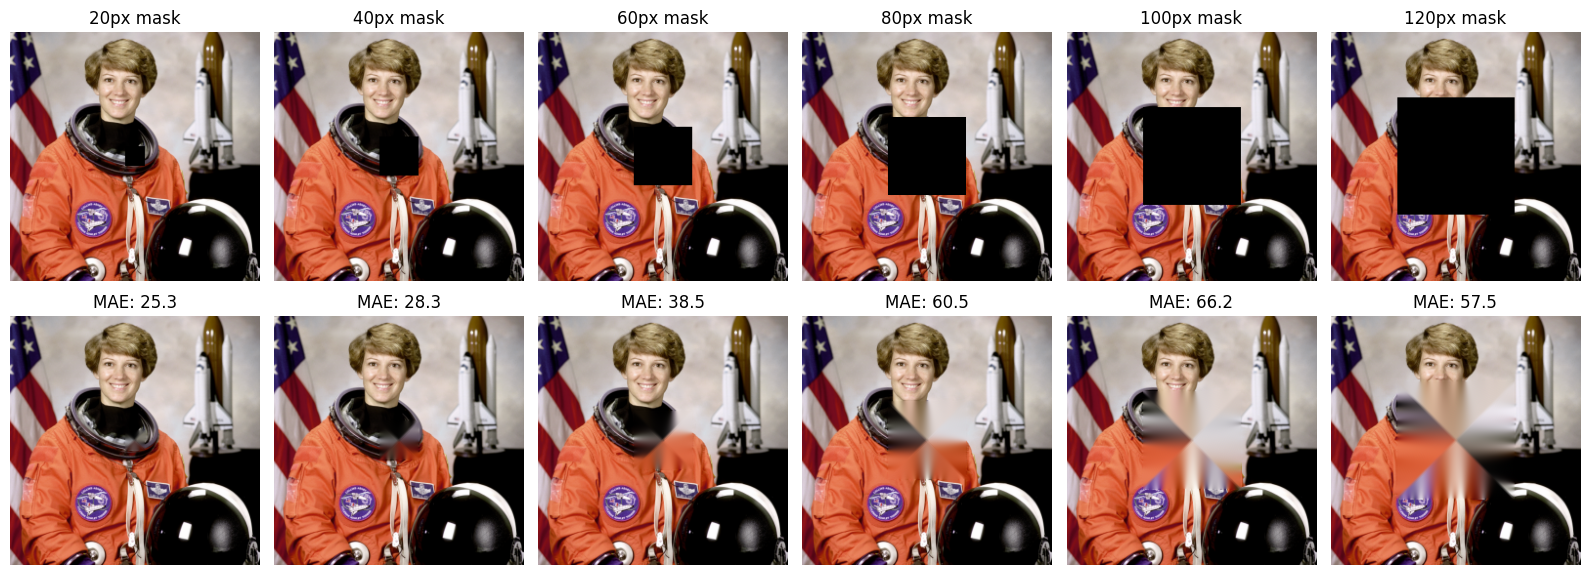

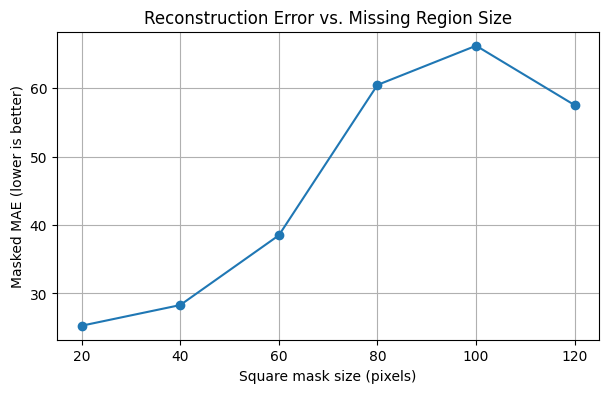

In [ ]:

# Compare different missing-region sizes

sizes = [20, 40, 60, 80, 100, 120]
results = []

fig, axes = plt.subplots(2, 6, figsize=(16, 6))

for i, size in enumerate(sizes):
    # Create a centered square mask
    mask_test = np.zeros((256, 256), dtype=np.uint8)

    start = (256 - size) // 2
    end = start + size
    mask_test[start:end, start:end] = 255

    # Create damaged image
    damaged_test = original.copy()
    damaged_test[mask_test > 0] = 0

    # Reconstruct
    restored_test = cv2.inpaint(
        cv2.cvtColor(damaged_test, cv2.COLOR_RGB2BGR),
        mask_test,
        3,
        cv2.INPAINT_TELEA
    )
    restored_test = cv2.cvtColor(
        restored_test, cv2.COLOR_BGR2RGB
    )

    # Measure error in the missing area
    missing = mask_test > 0
    mae = np.abs(
        original.astype(np.float32) -
        restored_test.astype(np.float32)
    )[missing].mean()

    results.append(mae)

    # Display damaged and restored images
    axes[0, i].imshow(damaged_test)
    axes[0, i].set_title(f"{size}px mask")
    axes[0, i].axis("off")

    axes[1, i].imshow(restored_test)
    axes[1, i].set_title(f"MAE: {mae:.1f}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

# Plot reconstruction error
plt.figure(figsize=(7, 4))
plt.plot(sizes, results, marker="o")
plt.xlabel("Square mask size (pixels)")
plt.ylabel("Masked MAE (lower is better)")
plt.title("Reconstruction Error vs. Missing Region Size")
plt.grid(True)
plt.show()


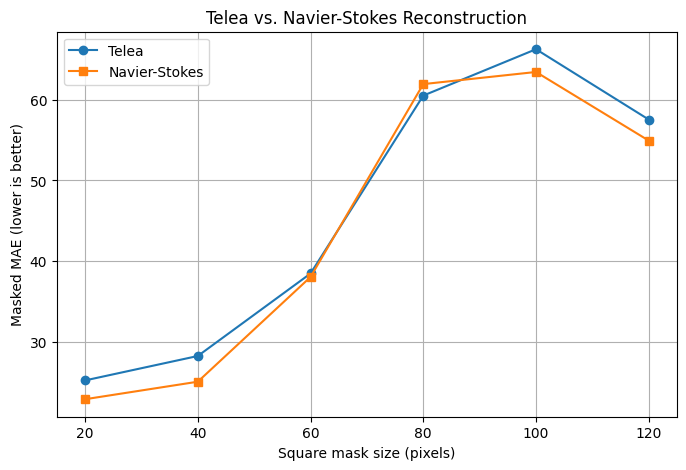

20px: Telea=25.28, NS=22.96, Winner=Navier-Stokes
40px: Telea=28.30, NS=25.12, Winner=Navier-Stokes
60px: Telea=38.50, NS=38.07, Winner=Navier-Stokes
80px: Telea=60.49, NS=61.91, Winner=Telea
100px: Telea=66.22, NS=63.41, Winner=Navier-Stokes
120px: Telea=57.53, NS=54.93, Winner=Navier-Stokes


In [ ]:

# Experiment 2: Telea vs Navier-Stokes

sizes = [20, 40, 60, 80, 100, 120]

telea_errors = []
ns_errors = []

for size in sizes:
    mask_test = np.zeros((256, 256), dtype=np.uint8)

    start = (256 - size) // 2
    end = start + size
    mask_test[start:end, start:end] = 255

    damaged_test = original.copy()
    damaged_test[mask_test > 0] = 0

    damaged_bgr = cv2.cvtColor(
        damaged_test, cv2.COLOR_RGB2BGR
    )

    # Method 1: Telea
    telea = cv2.inpaint(
        damaged_bgr, mask_test, 3, cv2.INPAINT_TELEA
    )

    # Method 2: Navier-Stokes
    ns = cv2.inpaint(
        damaged_bgr, mask_test, 3, cv2.INPAINT_NS
    )

    # Convert results to RGB
    telea = cv2.cvtColor(telea, cv2.COLOR_BGR2RGB)
    ns = cv2.cvtColor(ns, cv2.COLOR_BGR2RGB)

    missing = mask_test > 0

    # Calculate error for both methods
    telea_mae = np.abs(
        original.astype(np.float32) -
        telea.astype(np.float32)
    )[missing].mean()

    ns_mae = np.abs(
        original.astype(np.float32) -
        ns.astype(np.float32)
    )[missing].mean()

    telea_errors.append(telea_mae)
    ns_errors.append(ns_mae)

# Plot both algorithms
plt.figure(figsize=(8, 5))

plt.plot(
    sizes, telea_errors,
    marker="o", label="Telea"
)

plt.plot(
    sizes, ns_errors,
    marker="s", label="Navier-Stokes"
)

plt.xlabel("Square mask size (pixels)")
plt.ylabel("Masked MAE (lower is better)")
plt.title("Telea vs. Navier-Stokes Reconstruction")
plt.legend()
plt.grid(True)
plt.show()

# Print results
for size, t, n in zip(
    sizes, telea_errors, ns_errors
):
    winner = "Telea" if t < n else (
        "Navier-Stokes" if n < t else "Tie"
    )
    print(
        f"{size}px: Telea={t:.2f}, "
        f"NS={n:.2f}, Winner={winner}"
    )


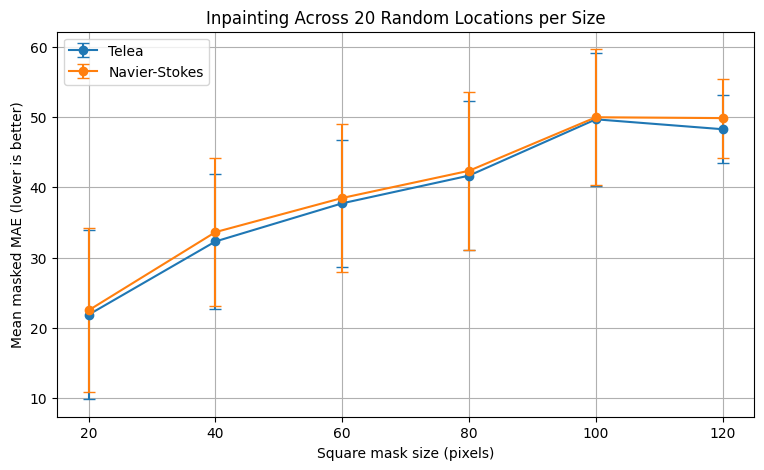

20px | Telea: 21.87 | NS: 22.49
40px | Telea: 32.28 | NS: 33.61
60px | Telea: 37.71 | NS: 38.47
80px | Telea: 41.65 | NS: 42.34
100px | Telea: 49.65 | NS: 49.94
120px | Telea: 48.24 | NS: 49.82


In [ ]:

# Experiment 3: Random mask positions
# Compare Telea and Navier-Stokes fairly

import numpy as np
import cv2
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

sizes = [20, 40, 60, 80, 100, 120]
n_trials = 20

results = {"Telea": [], "Navier-Stokes": []}
stds = {"Telea": [], "Navier-Stokes": []}

h, w = original.shape[:2]

for size in sizes:
    telea_scores = []
    ns_scores = []

    for trial in range(n_trials):
        # Randomly position a square mask
        x = rng.integers(0, w - size + 1)
        y = rng.integers(0, h - size + 1)

        mask = np.zeros((h, w), dtype=np.uint8)
        mask[y:y+size, x:x+size] = 255

        damaged = original.copy()
        damaged[mask > 0] = 0

        damaged_bgr = cv2.cvtColor(
            damaged, cv2.COLOR_RGB2BGR
        )

        # Run both algorithms
        for method, flag in [
            ("Telea", cv2.INPAINT_TELEA),
            ("Navier-Stokes", cv2.INPAINT_NS)
        ]:
            restored_bgr = cv2.inpaint(
                damaged_bgr, mask, 3, flag
            )

            restored = cv2.cvtColor(
                restored_bgr, cv2.COLOR_BGR2RGB
            )

            error = np.abs(
                original.astype(np.float32) -
                restored.astype(np.float32)
            )

            mae = error[mask > 0].mean()

            if method == "Telea":
                telea_scores.append(mae)
            else:
                ns_scores.append(mae)

    for name, scores in [
        ("Telea", telea_scores),
        ("Navier-Stokes", ns_scores)
    ]:
        results[name].append(np.mean(scores))
        stds[name].append(np.std(scores, ddof=1))

# Plot means with standard deviation
plt.figure(figsize=(9, 5))

for name in results:
    plt.errorbar(
        sizes,
        results[name],
        yerr=stds[name],
        marker="o",
        capsize=4,
        label=name
    )

plt.xlabel("Square mask size (pixels)")
plt.ylabel("Mean masked MAE (lower is better)")
plt.title("Inpainting Across 20 Random Locations per Size")
plt.legend()
plt.grid(True)
plt.show()

# Show results
for i, size in enumerate(sizes):
    print(
        f"{size}px | "
        f"Telea: {results['Telea'][i]:.2f} | "
        f"NS: {results['Navier-Stokes'][i]:.2f}"
    )


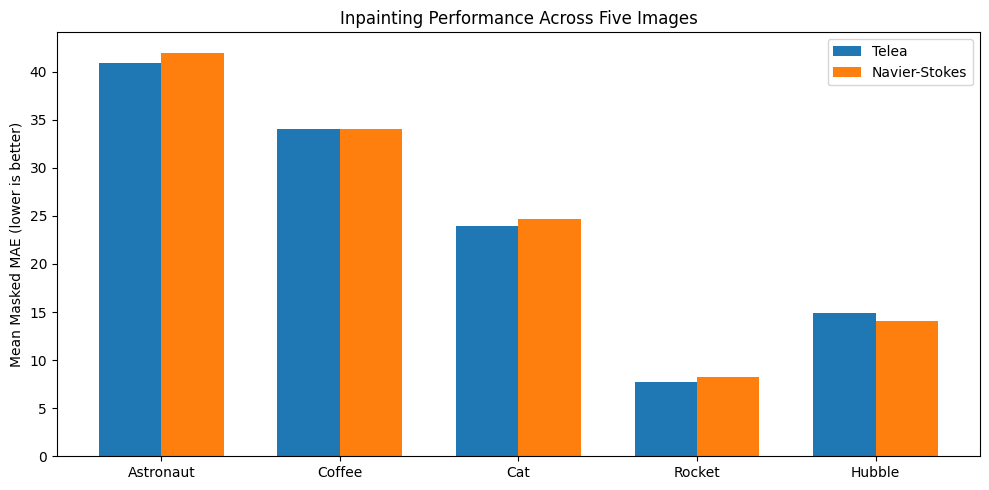

Astronaut: Telea=40.90, NS=41.98, Winner=Telea
Coffee: Telea=34.01, NS=34.07, Winner=Telea
Cat: Telea=23.90, NS=24.67, Winner=Telea
Rocket: Telea=7.70, NS=8.26, Winner=Telea
Hubble: Telea=14.87, NS=14.08, Winner=Navier-Stokes


In [ ]:

# Experiment 4: Compare algorithms across multiple images

from skimage import data
from skimage.transform import resize
import numpy as np
import cv2
import matplotlib.pyplot as plt

# Five different images
image_sources = {
    "Astronaut": data.astronaut(),
    "Coffee": data.coffee(),
    "Cat": data.chelsea(),
    "Rocket": data.rocket(),
    "Hubble": data.hubble_deep_field()
}

# Prepare RGB images at the same resolution
images = {}

for name, img in image_sources.items():
    img = resize(
        img,
        (256, 256),
        preserve_range=True,
        anti_aliasing=True
    ).astype(np.uint8)

    images[name] = img

rng = np.random.default_rng(42)
mask_size = 80
n_trials = 20

summary = {}

for name, original_img in images.items():

    telea_scores = []
    ns_scores = []

    for trial in range(n_trials):

        h, w = original_img.shape[:2]

        x = rng.integers(0, w - mask_size + 1)
        y = rng.integers(0, h - mask_size + 1)

        mask = np.zeros((h, w), dtype=np.uint8)
        mask[y:y+mask_size, x:x+mask_size] = 255

        damaged = original_img.copy()
        damaged[mask > 0] = 0

        damaged_bgr = cv2.cvtColor(
            damaged, cv2.COLOR_RGB2BGR
        )

        scores = {}

        for method, flag in [
            ("Telea", cv2.INPAINT_TELEA),
            ("Navier-Stokes", cv2.INPAINT_NS)
        ]:

            restored_bgr = cv2.inpaint(
                damaged_bgr, mask, 3, flag
            )

            restored = cv2.cvtColor(
                restored_bgr, cv2.COLOR_BGR2RGB
            )

            error = np.abs(
                original_img.astype(np.float32) -
                restored.astype(np.float32)
            )

            scores[method] = error[mask > 0].mean()

        telea_scores.append(scores["Telea"])
        ns_scores.append(scores["Navier-Stokes"])

    summary[name] = {
        "Telea": np.mean(telea_scores),
        "Navier-Stokes": np.mean(ns_scores)
    }

# Display results
names = list(summary.keys())

telea = [summary[n]["Telea"] for n in names]
ns = [summary[n]["Navier-Stokes"] for n in names]

x = np.arange(len(names))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, telea, width, label="Telea")
plt.bar(x + width/2, ns, width, label="Navier-Stokes")

plt.xticks(x, names)
plt.ylabel("Mean Masked MAE (lower is better)")
plt.title("Inpainting Performance Across Five Images")
plt.legend()
plt.tight_layout()
plt.show()

for name in names:
    t = summary[name]["Telea"]
    n = summary[name]["Navier-Stokes"]

    winner = "Telea" if t < n else (
        "Navier-Stokes" if n < t else "Tie"
    )

    print(
        f"{name}: Telea={t:.2f}, "
        f"NS={n:.2f}, Winner={winner}"
    )


In [ ]:

import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


PyTorch version: 2.14.1+cu130
GPU available: True
GPU name: Tesla T4


In [9]:

import torch
import torchvision
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

# Resize images and convert them into tensors
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Download the training dataset
dataset = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True,
    transform=transform
)

# Split into training and validation sets
generator = torch.Generator().manual_seed(42)

train_size = int(0.9 * len(dataset))
val_size = len(dataset) - train_size

train_dataset, val_dataset = random_split(
    dataset,
    [train_size, val_size],
    generator=generator
)

# Create data loaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")



Training images: 3312
Validation images: 368
Device: cpu


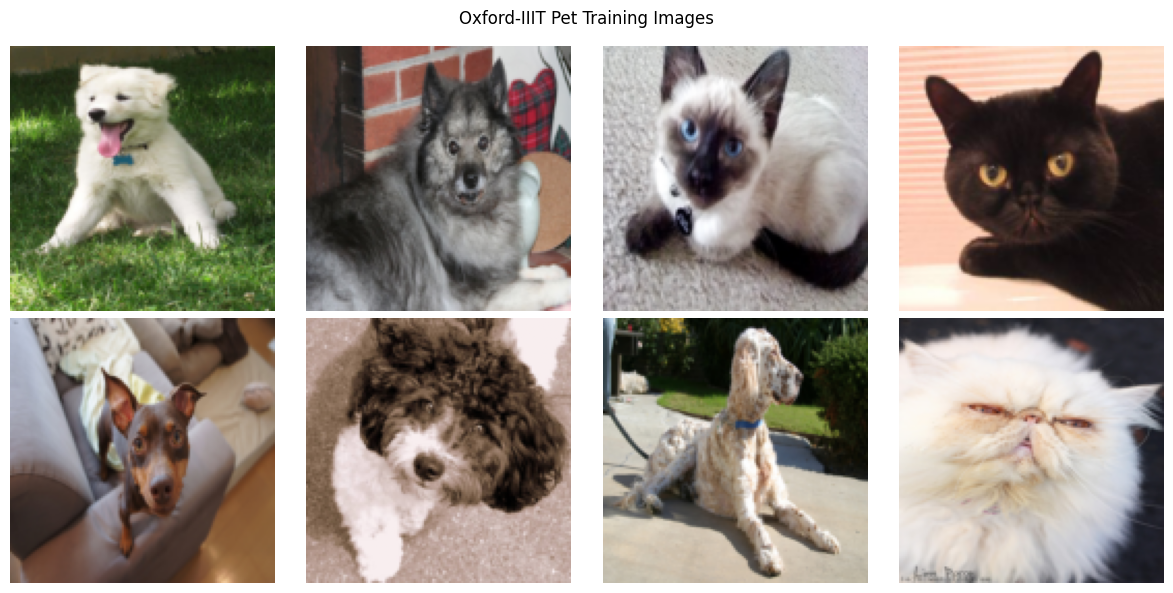

Batch shape: torch.Size([16, 3, 128, 128])


In [3]:

import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.axis("off")

plt.suptitle("Oxford-IIIT Pet Training Images")
plt.tight_layout()
plt.show()

print("Batch shape:", images.shape)


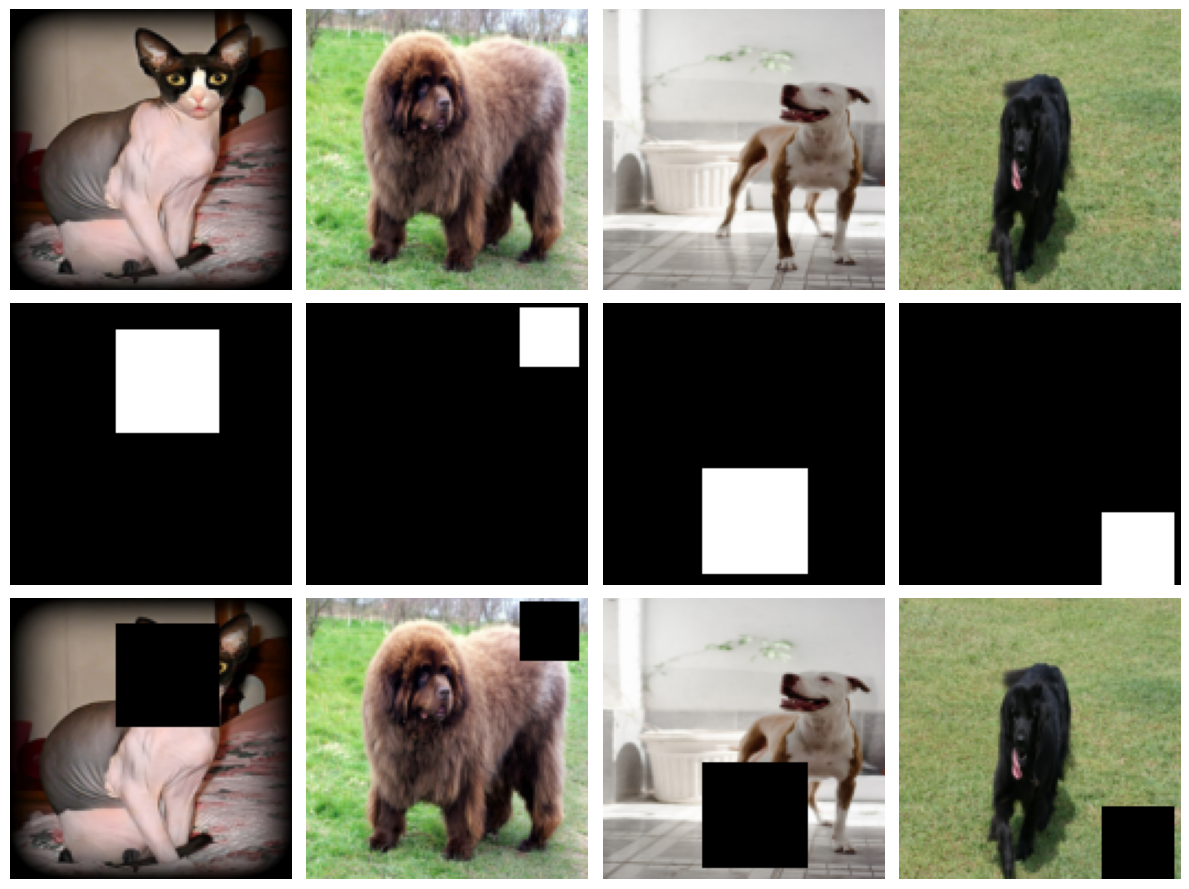

Original shape: torch.Size([16, 3, 128, 128])
Mask shape: torch.Size([16, 1, 128, 128])
Damaged shape: torch.Size([16, 3, 128, 128])


In [10]:

import torch
import matplotlib.pyplot as plt

# Create random square masks for a batch of images
def create_random_masks(images, min_size=20, max_size=60):
    batch_size, channels, height, width = images.shape

    masks = torch.zeros(
        batch_size, 1, height, width,
        dtype=images.dtype,
        device=images.device
    )

    for i in range(batch_size):
        size = torch.randint(
            min_size, max_size + 1, (1,)
        ).item()

        x = torch.randint(
            0, width - size + 1, (1,)
        ).item()

        y = torch.randint(
            0, height - size + 1, (1,)
        ).item()

        masks[i, :, y:y+size, x:x+size] = 1.0

    return masks


# Get a batch from our dataset
images, labels = next(iter(train_loader))

# Generate masks
masks = create_random_masks(images)

# Remove missing pixels
damaged_images = images * (1 - masks)

# Visualize original, mask and damaged image
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i in range(4):
    axes[0, i].imshow(
        images[i].permute(1, 2, 0)
    )

    axes[1, i].imshow(
        masks[i, 0], cmap="gray",
        vmin=0, vmax=1
    )

    axes[2, i].imshow(
        damaged_images[i].permute(1, 2, 0)
    )

    for row in range(3):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Mask")
axes[2, 0].set_ylabel("Damaged")

plt.tight_layout()
plt.show()

print("Original shape:", images.shape)
print("Mask shape:", masks.shape)
print("Damaged shape:", damaged_images.shape)


In [11]:

import torch
import torch.nn as nn

# Two convolution layers that learn image features
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, 3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)


# Small U-Net for 128x128 image reconstruction
class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(4, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(128, 256)

        # Decoder
        self.up3 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec3 = DoubleConv(256, 128)

        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = DoubleConv(128, 64)

        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = DoubleConv(64, 32)

        # Final RGB prediction
        self.output = nn.Conv2d(32, 3, 1)

    def forward(self, x):
        # Encoding
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))

        # Bottleneck
        b = self.bottleneck(self.pool(e3))

        # Decoding with skip connections
        d3 = self.up3(b)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))

        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))

        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return torch.sigmoid(self.output(d1))


# Create model on GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SmallUNet().to(device)

print("Model created successfully!")
print("Total parameters:", sum(
    p.numel() for p in model.parameters()
))


Model created successfully!
Total parameters: 1925955


Model input: torch.Size([16, 4, 128, 128])
Model output: torch.Size([16, 3, 128, 128])
Prediction range: 0.4560016393661499 0.4920079708099365
Epoch 1/5 | Train Loss: 0.1665 | Val Loss: 0.1381
Epoch 2/5 | Train Loss: 0.1293 | Val Loss: 0.1303
Epoch 3/5 | Train Loss: 0.1264 | Val Loss: 0.1254
Epoch 4/5 | Train Loss: 0.1228 | Val Loss: 0.1236
Epoch 5/5 | Train Loss: 0.1215 | Val Loss: 0.1208


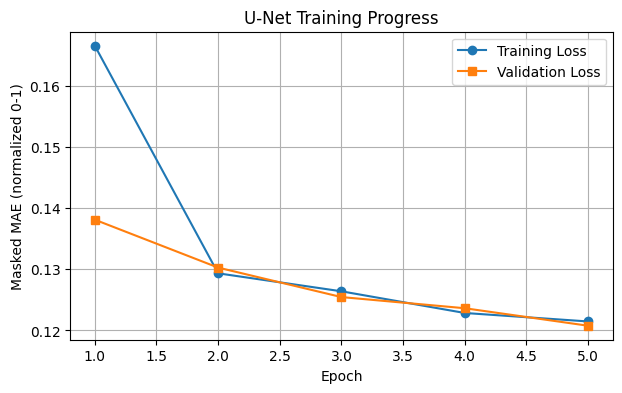

In [7]:

# Test our model using one batch

images, labels = next(iter(train_loader))

images = images.to(device)

# Generate random missing regions
masks = create_random_masks(images)

# Remove the masked pixels
damaged = images * (1 - masks)

# Combine RGB image (3 channels) + mask (1 channel)
model_input = torch.cat(
    [damaged, masks], dim=1
)

# Test without training
model.eval()

with torch.no_grad():
    predictions = model(model_input)

print("Model input:", model_input.shape)
print("Model output:", predictions.shape)
print("Prediction range:",
      predictions.min().item(),
      predictions.max().item())

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# Training settings
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

num_epochs = 5

train_losses = []
val_losses = []

# Loss focuses only on missing pixels
def masked_loss(predictions, originals, masks):
    error = torch.abs(predictions - originals) * masks

    return error.sum() / (
        masks.sum() * originals.shape[1] + 1e-8
    )

# Train model
for epoch in range(num_epochs):

    model.train()
    total_train_loss = 0

    for images, _ in train_loader:
        images = images.to(device)

        masks = create_random_masks(images)
        damaged = images * (1 - masks)

        inputs = torch.cat([damaged, masks], dim=1)

        predictions = model(inputs)
        loss = masked_loss(predictions, images, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    train_loss = total_train_loss / len(train_loader)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    total_val_loss = 0

    with torch.no_grad():
        for images, _ in val_loader:
            images = images.to(device)

            masks = create_random_masks(images)
            damaged = images * (1 - masks)

            inputs = torch.cat([damaged, masks], dim=1)

            predictions = model(inputs)
            loss = masked_loss(predictions, images, masks)

            total_val_loss += loss.item()

    val_loss = total_val_loss / len(val_loader)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}"
    )

# Plot training results
plt.figure(figsize=(7, 4))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Masked MAE (normalized 0-1)")
plt.title("U-Net Training Progress")
plt.legend()
plt.grid(True)
plt.show()


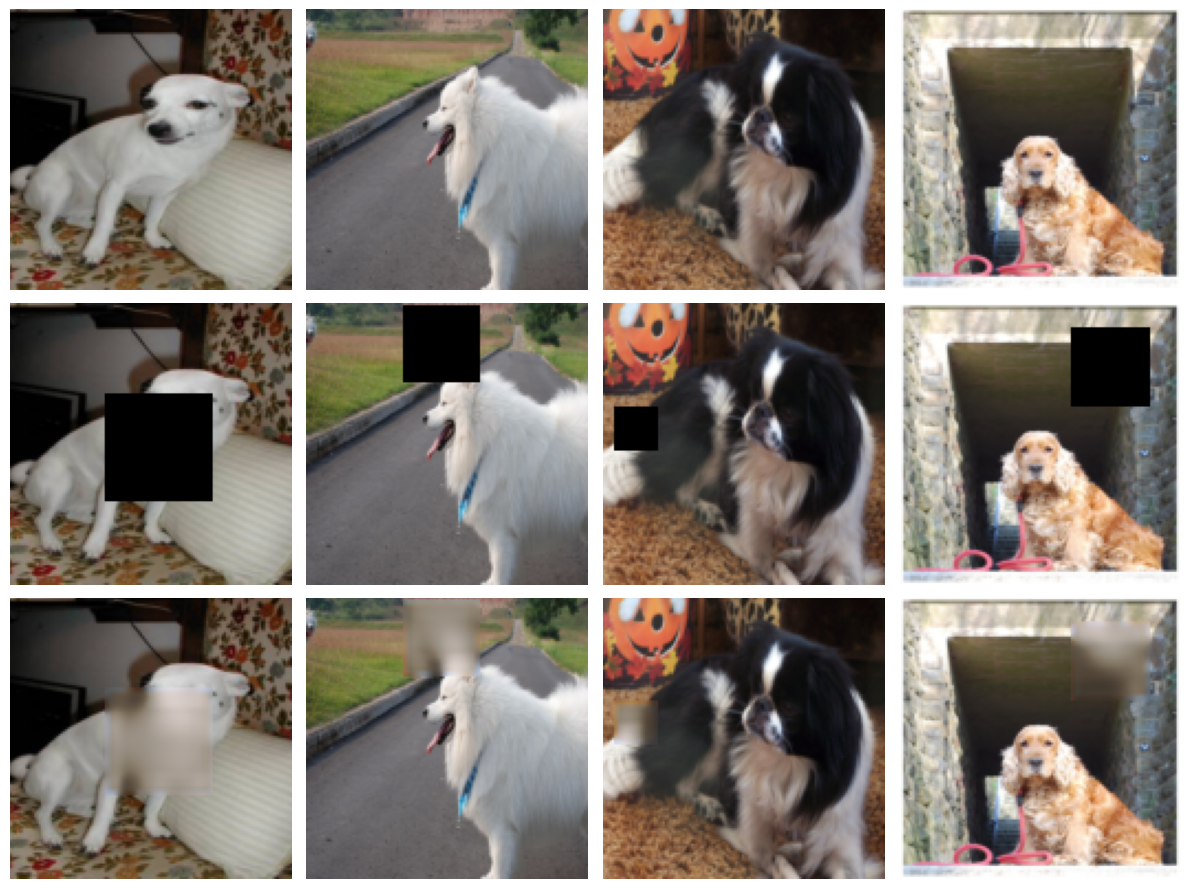

In [8]:

# Visualize U-Net reconstructions

model.eval()

# Get validation images
images, labels = next(iter(val_loader))
images = images.to(device)

# Generate random missing regions
masks = create_random_masks(images)
damaged = images * (1 - masks)

# Combine damaged RGB + mask
inputs = torch.cat([damaged, masks], dim=1)

# Generate reconstructions
with torch.no_grad():
    predictions = model(inputs)

# Preserve original pixels outside missing regions
restored = damaged + predictions * masks

# Move results to CPU for visualization
originals_np = images.cpu()
damaged_np = damaged.cpu()
restored_np = restored.cpu()

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i in range(4):
    axes[0, i].imshow(
        originals_np[i].permute(1, 2, 0)
    )

    axes[1, i].imshow(
        damaged_np[i].permute(1, 2, 0)
    )

    axes[2, i].imshow(
        restored_np[i].permute(1, 2, 0)
    )

    for row in range(3):
        axes[row, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Damaged")
axes[2, 0].set_ylabel("U-Net Restored")

plt.tight_layout()
plt.show()


U-Net: Mean MAE = 0.0025
Telea: Mean MAE = 0.0022
Navier-Stokes: Mean MAE = 0.0022


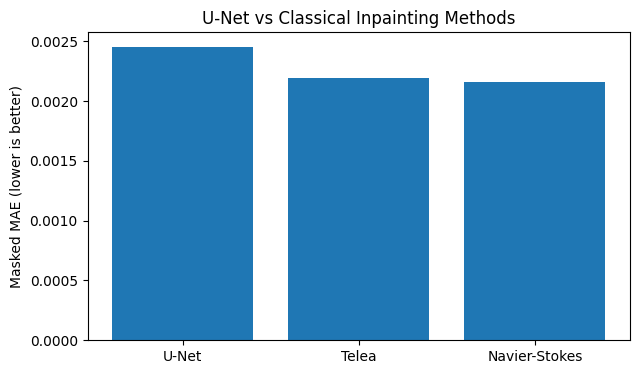

In [9]:

import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt

model.eval()

# Use validation images
images, _ = next(iter(val_loader))
images = images.to(device)

# Create the same masks for all three methods
torch.manual_seed(42)
masks = create_random_masks(images)

damaged = images * (1 - masks)
model_input = torch.cat([damaged, masks], dim=1)

# U-Net reconstruction
with torch.no_grad():
    predictions = model(model_input)

unet_restored = damaged + predictions * masks

# Calculate masked MAE
def calculate_mae(original, restored, mask):
    error = torch.abs(original - restored) * mask

    return (
        error.sum() /
        (mask.sum() * original.shape[1])
    ).item()

results = {
    "U-Net": [],
    "Telea": [],
    "Navier-Stokes": []
}

# Evaluate each image
for i in range(len(images)):
    original = images[i].cpu()
    mask = masks[i].cpu()

    # U-Net
    unet_img = unet_restored[i].cpu()

    results["U-Net"].append(
        calculate_mae(original, unet_img, mask)
    )

    # Convert image to uint8 for OpenCV
    original_np = (
        original.permute(1, 2, 0).numpy() * 255
    ).astype(np.uint8)

    mask_np = (
        mask[0].numpy() * 255
    ).astype(np.uint8)

    damaged_np = original_np.copy()
    damaged_np[mask_np > 0] = 0

    damaged_bgr = cv2.cvtColor(
        damaged_np, cv2.COLOR_RGB2BGR
    )

    for method, flag in [
        ("Telea", cv2.INPAINT_TELEA),
        ("Navier-Stokes", cv2.INPAINT_NS)
    ]:
        restored_bgr = cv2.inpaint(
            damaged_bgr,
            mask_np,
            3,
            flag
        )

        restored_rgb = cv2.cvtColor(
            restored_bgr, cv2.COLOR_BGR2RGB
        )

        restored_tensor = torch.from_numpy(
            restored_rgb.astype(np.float32) / 255
        ).permute(2, 0, 1)

        results[method].append(
            calculate_mae(
                original,
                restored_tensor,
                mask
            )
        )

# Print benchmark results
for method, scores in results.items():
    print(
        f"{method}: Mean MAE = "
        f"{np.mean(scores):.4f}"
    )

# Plot results
plt.figure(figsize=(7, 4))

methods = list(results.keys())
means = [np.mean(results[m]) for m in methods]

plt.bar(methods, means)

plt.ylabel("Masked MAE (lower is better)")
plt.title("U-Net vs Classical Inpainting Methods")
plt.show()


In [10]:

# Diagnostic: verify masked reconstruction error

# Use the images, masks and reconstructions
# from our previous comparison cell

print("Image shape:", images.shape)
print("Mask shape:", masks.shape)

print("Mask values:", torch.unique(masks).tolist())

# Percentage of missing pixels
missing_fraction = masks.mean().item()

print(
    f"Missing image area: {missing_fraction * 100:.2f}%"
)

# Calculate masked MAE directly
absolute_error = torch.abs(images - unet_restored)

# All-pixel MAE (includes unchanged pixels)
full_mae = absolute_error.mean().item()

# Masked MAE (only missing pixels)
missing_pixels = masks.expand_as(absolute_error) > 0

masked_mae = absolute_error[missing_pixels].mean().item()

print(f"Full-image MAE: {full_mae:.4f}")
print(f"Masked-region MAE: {masked_mae:.4f}")

# Compare with our training loss definition
with torch.no_grad():
    predicted_mae = masked_loss(
        predictions, images, masks
    ).item()

print(f"Prediction masked loss: {predicted_mae:.4f}")


Image shape: torch.Size([16, 3, 128, 128])
Mask shape: torch.Size([16, 1, 128, 128])
Mask values: [0.0, 1.0]
Missing image area: 7.67%
Full-image MAE: 0.0086
Masked-region MAE: 0.1115
Prediction masked loss: 0.1115


In [1]:

print("Model available:", "model" in globals())
print("Images available:", "images" in globals())
print("Masks available:", "masks" in globals())

if "model" in globals():
    model = model.to("cpu")
    print("Model moved to CPU")


Model available: False
Images available: False
Masks available: False


In [2]:

import os

# Look for saved model files
for folder in ["/content", "/content/drive/MyDrive"]:
    if not os.path.exists(folder):
        continue

    for root, dirs, files in os.walk(folder):
        for filename in files:
            if filename.endswith((".pth", ".pt")):
                print(os.path.join(root, filename))


In [3]:

from google.colab import drive
import os

# Connect Google Drive
drive.mount('/content/drive')

# Search for saved PyTorch models
found = []

for root, dirs, files in os.walk(
    '/content/drive/MyDrive'
):
    for filename in files:
        if filename.endswith(('.pth', '.pt')):
            found.append(os.path.join(root, filename))

if found:
    print("Found model checkpoints:")
    for path in found:
        print(path)
else:
    print("No saved checkpoints found.")


Mounted at /content/drive
No saved checkpoints found.


In [4]:

import torch

def calculate_mae(original, restored, mask):
    error = torch.abs(original - restored)
    missing = mask.expand_as(error) > 0
    return error[missing].mean().item()

# Test the function with a known example
original = torch.zeros(3, 4, 4)
restored = original.clone()

mask = torch.zeros(1, 4, 4)
mask[:, 1:3, 1:3] = 1

# Make every missing RGB pixel differ by 0.5
restored[:, 1:3, 1:3] = 0.5

score = calculate_mae(original, restored, mask)

print("Calculated masked MAE:", score)
print("Expected masked MAE: 0.5")

assert abs(score - 0.5) < 1e-6
print("Evaluation test passed!")


Calculated masked MAE: 0.5
Expected masked MAE: 0.5
Evaluation test passed!


In [5]:

import os

project_dir = "/content/drive/MyDrive/image_reconstruction"
os.makedirs(project_dir, exist_ok=True)

print("Project folder:", project_dir)


Project folder: /content/drive/MyDrive/image_reconstruction


In [12]:

import torch
import os

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Device:", device)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))
print("Project folder exists:", os.path.exists(project_dir))

assert os.path.exists(project_dir)
print("Ready to train!")


Device: cpu
Training images: 3312
Validation images: 368
Project folder exists: True
Ready to train!


In [13]:

import os
import torch
from torch.utils.data import DataLoader, Subset

# Where checkpoints will be saved
project_dir = "/content/drive/MyDrive/image_reconstruction"
os.makedirs(project_dir, exist_ok=True)

checkpoint_path = os.path.join(
    project_dir, "unet_checkpoint.pth"
)

# Use a smaller dataset for CPU training
small_train = Subset(train_dataset, range(500))

small_loader = DataLoader(
    small_train,
    batch_size=8,
    shuffle=True,
    num_workers=2
)

optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

def masked_loss(predictions, originals, masks):
    error = torch.abs(predictions - originals) * masks
    return error.sum() / (
        masks.sum() * originals.shape[1] + 1e-8
    )

print("Device:", device)
print("Training images:", len(small_train))
print("Checkpoint path:", checkpoint_path)


Device: cpu
Training images: 500
Checkpoint path: /content/drive/MyDrive/image_reconstruction/unet_checkpoint.pth


In [14]:

num_epochs = 3

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    for images, _ in small_loader:
        images = images.to(device)

        masks = create_random_masks(images)
        damaged = images * (1 - masks)

        inputs = torch.cat([damaged, masks], dim=1)

        predictions = model(inputs)
        loss = masked_loss(predictions, images, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(small_loader)

    # Save checkpoint to Google Drive
    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": avg_loss
    }, checkpoint_path)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {avg_loss:.4f} | "
        f"Checkpoint saved!"
    )


Epoch 1/3 | Train Loss: 0.2074 | Checkpoint saved!
Epoch 2/3 | Train Loss: 0.1704 | Checkpoint saved!
Epoch 3/3 | Train Loss: 0.1540 | Checkpoint saved!


In [15]:

import os
import torch

checkpoint_path = (
    "/content/drive/MyDrive/"
    "image_reconstruction/unet_checkpoint.pth"
)

assert os.path.isfile(checkpoint_path), \
    "Checkpoint not found!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint found!")
print("Saved epoch:", checkpoint["epoch"])
print("Saved training loss:", checkpoint["train_loss"])
print(
    "File size:",
    round(os.path.getsize(checkpoint_path) / 1e6, 2),
    "MB"
)


Checkpoint found!
Saved epoch: 3
Saved training loss: 0.1539724153422174
File size: 23.16 MB


In [16]:

def calculate_mae(original, restored, mask):
    error = torch.abs(original - restored)
    missing = mask.expand_as(error) > 0

    return error[missing].mean().item()


# Verify with a known example
original_test = torch.zeros(3, 4, 4)
restored_test = original_test.clone()

mask_test = torch.zeros(1, 4, 4)
mask_test[:, 1:3, 1:3] = 1

restored_test[:, 1:3, 1:3] = 0.5

score = calculate_mae(
    original_test,
    restored_test,
    mask_test
)

assert abs(score - 0.5) < 1e-6

print("Corrected MAE function verified!")


Corrected MAE function verified!


In [17]:

import torch
import os

checkpoint_path = (
    "/content/drive/MyDrive/"
    "image_reconstruction/unet_checkpoint.pth"
)

assert os.path.isfile(checkpoint_path), "Checkpoint not found!"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

print("Checkpoint loaded!")
print("Saved epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])


Checkpoint loaded!
Saved epoch: 3
Training loss: 0.1539724153422174


U-Net: Mean masked MAE = 0.1256
Telea: Mean masked MAE = 0.0934
Navier-Stokes: Mean masked MAE = 0.0922


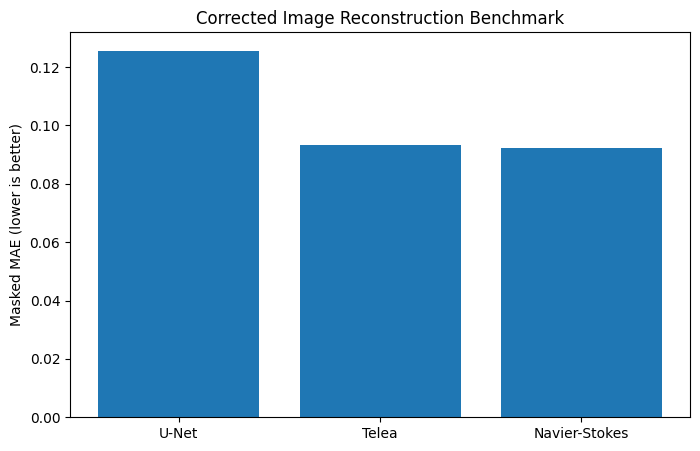

In [18]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

# Use the same 16 validation images for all methods
images, _ = next(iter(val_loader))
images = images.to("cpu")

# Make masks reproducible
torch.manual_seed(42)
masks = create_random_masks(images)

damaged = images * (1 - masks)
inputs = torch.cat([damaged, masks], dim=1)

# U-Net predictions
model.eval()
with torch.no_grad():
    predictions = model(inputs)

unet_restored = damaged + predictions * masks

results = {
    "U-Net": [],
    "Telea": [],
    "Navier-Stokes": []
}

for i in range(len(images)):
    original = images[i]
    mask = masks[i]

    # Evaluate U-Net
    results["U-Net"].append(
        calculate_mae(original, unet_restored[i], mask)
    )

    # Prepare the OpenCV input
    original_np = (
        original.permute(1, 2, 0).numpy() * 255
    ).round().astype(np.uint8)

    mask_np = (mask[0].numpy() * 255).astype(np.uint8)

    damaged_np = original_np.copy()
    damaged_np[mask_np > 0] = 0

    damaged_bgr = cv2.cvtColor(
        damaged_np, cv2.COLOR_RGB2BGR
    )

    for method, flag in [
        ("Telea", cv2.INPAINT_TELEA),
        ("Navier-Stokes", cv2.INPAINT_NS)
    ]:
        reconstructed_bgr = cv2.inpaint(
            damaged_bgr, mask_np, 3, flag
        )

        reconstructed_rgb = cv2.cvtColor(
            reconstructed_bgr, cv2.COLOR_BGR2RGB
        )

        reconstructed_tensor = torch.from_numpy(
            reconstructed_rgb.astype(np.float32) / 255
        ).permute(2, 0, 1)

        results[method].append(
            calculate_mae(
                original,
                reconstructed_tensor,
                mask
            )
        )

# Display results
for method, scores in results.items():
    print(
        f"{method}: Mean masked MAE = "
        f"{np.mean(scores):.4f}"
    )

# Plot
plt.figure(figsize=(8, 5))
plt.bar(
    list(results.keys()),
    [np.mean(v) for v in results.values()]
)
plt.ylabel("Masked MAE (lower is better)")
plt.title("Corrected Image Reconstruction Benchmark")
plt.show()


In [19]:

import numpy as np
import torch
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Reproducible masks
torch.manual_seed(42)

model.eval()
model = model.to("cpu")

all_results = {
    "U-Net": [],
    "Telea": [],
    "Navier-Stokes": []
}

for images, _ in val_loader:
    images = images.to("cpu")
    masks = create_random_masks(images)

    damaged = images * (1 - masks)
    inputs = torch.cat([damaged, masks], dim=1)

    with torch.no_grad():
        predictions = model(inputs)

    restored_unet = damaged + predictions * masks

    for i in range(len(images)):
        original = images[i]
        mask = masks[i]

        all_results["U-Net"].append(
            calculate_mae(
                original, restored_unet[i], mask
            )
        )

        original_np = (
            original.permute(1, 2, 0).numpy() * 255
        ).round().astype(np.uint8)

        mask_np = (
            mask[0].numpy() * 255
        ).astype(np.uint8)

        damaged_np = original_np.copy()
        damaged_np[mask_np > 0] = 0

        damaged_bgr = cv2.cvtColor(
            damaged_np, cv2.COLOR_RGB2BGR
        )

        for method, flag in [
            ("Telea", cv2.INPAINT_TELEA),
            ("Navier-Stokes", cv2.INPAINT_NS)
        ]:
            restored_bgr = cv2.inpaint(
                damaged_bgr, mask_np, 3, flag
            )

            restored_rgb = cv2.cvtColor(
                restored_bgr, cv2.COLOR_BGR2RGB
            )

            restored_tensor = torch.from_numpy(
                restored_rgb.astype(np.float32) / 255
            ).permute(2, 0, 1)

            all_results[method].append(
                calculate_mae(
                    original, restored_tensor, mask
                )
            )

# Summary table
summary = pd.DataFrame({
    "Method": list(all_results.keys()),
    "Mean MAE": [
        np.mean(scores)
        for scores in all_results.values()
    ],
    "Std Dev": [
        np.std(scores, ddof=1)
        for scores in all_results.values()
    ]
})

print(summary.to_string(index=False))

# Save results permanently
summary.to_csv(
    project_dir + "/validation_benchmark.csv",
    index=False
)

print("\nSaved benchmark to Google Drive!")


       Method  Mean MAE  Std Dev
        U-Net  0.144720 0.046721
        Telea  0.103539 0.043700
Navier-Stokes  0.105177 0.045206

Saved benchmark to Google Drive!


In [20]:

import os
import shutil

baseline_path = os.path.join(
    project_dir, "unet_baseline_3epochs.pth"
)

shutil.copy2(
    checkpoint_path,
    baseline_path
)

print("Baseline model saved!")
print("Location:", baseline_path)


Baseline model saved!
Location: /content/drive/MyDrive/image_reconstruction/unet_baseline_3epochs.pth


In [21]:

import pandas as pd
import os

detailed_results = pd.DataFrame({
    "image_id": range(len(all_results["U-Net"])),
    "unet_mae": all_results["U-Net"],
    "telea_mae": all_results["Telea"],
    "navier_stokes_mae": all_results["Navier-Stokes"]
})

detailed_path = os.path.join(
    project_dir, "validation_detailed_results.csv"
)

detailed_results.to_csv(
    detailed_path,
    index=False
)

print("Detailed results saved!")
print("Images evaluated:", len(detailed_results))
print("Location:", detailed_path)


Detailed results saved!
Images evaluated: 368
Location: /content/drive/MyDrive/image_reconstruction/validation_detailed_results.csv


In [22]:

import os
import torch
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

baseline_path = os.path.join(
    project_dir, "unet_baseline_3epochs.pth"
)

checkpoint = torch.load(
    baseline_path,
    map_location=device,
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0003
)

print("Baseline loaded successfully!")
print("Device:", device)
print("Starting from saved epoch:", checkpoint["epoch"])


Baseline loaded successfully!
Device: cpu
Starting from saved epoch: 3


In [23]:

import time

num_epochs = 5

improved_path = os.path.join(
    project_dir, "unet_improved.pth"
)

for epoch in range(num_epochs):
    model.train()
    total_loss = 0

    start_time = time.time()

    for images, _ in train_loader:
        images = images.to(device)

        masks = create_random_masks(images)
        damaged = images * (1 - masks)

        inputs = torch.cat(
            [damaged, masks], dim=1
        )

        predictions = model(inputs)
        loss = masked_loss(
            predictions, images, masks
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    torch.save({
        "epoch": epoch + 1,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "train_loss": avg_loss
    }, improved_path)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Loss: {avg_loss:.4f} | "
        f"Time: {elapsed:.1f}s | "
        "Checkpoint saved!"
    )


Epoch 1/5 | Loss: 0.1347 | Time: 1426.0s | Checkpoint saved!


KeyboardInterrupt: 

In [24]:

import os
import torch

improved_path = os.path.join(
    project_dir, "unet_improved.pth"
)

checkpoint = torch.load(
    improved_path,
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

print("Improved checkpoint loaded!")
print("Completed epochs in new phase:", checkpoint["epoch"])
print("Training loss:", checkpoint["train_loss"])


Improved checkpoint loaded!
Completed epochs in new phase: 1
Training loss: 0.13470891298015336


In [25]:

import numpy as np
import pandas as pd

# Keep the same mask-generation seed and validation loader
# as your previous 368-image benchmark.
torch.manual_seed(42)

improved_mae = []

model.eval()

with torch.no_grad():
    for images, _ in val_loader:
        images = images.to("cpu")
        masks = create_random_masks(images)

        damaged = images * (1 - masks)
        inputs = torch.cat([damaged, masks], dim=1)

        predictions = model(inputs)
        restored = damaged + predictions * masks

        for i in range(len(images)):
            improved_mae.append(
                calculate_mae(
                    images[i],
                    restored[i],
                    masks[i]
                )
            )

baseline_results = pd.read_csv(
    os.path.join(
        project_dir,
        "validation_detailed_results.csv"
    )
)

baseline_mae = baseline_results["unet_mae"].mean()
new_mae = np.mean(improved_mae)

print(f"Baseline U-Net MAE: {baseline_mae:.4f}")
print(f"Improved U-Net MAE: {new_mae:.4f}")
print(f"Telea MAE:          {baseline_results['telea_mae'].mean():.4f}")
print(f"Navier-Stokes MAE:  {baseline_results['navier_stokes_mae'].mean():.4f}")

improvement = (baseline_mae - new_mae) / baseline_mae * 100

print(f"\nU-Net error reduction: {improvement:.2f}%")


Baseline U-Net MAE: 0.1447
Improved U-Net MAE: 0.1214
Telea MAE:          0.1035
Navier-Stokes MAE:  0.1052

U-Net error reduction: 16.14%


In [26]:

import os
import pandas as pd
import numpy as np

comparison = baseline_results.copy()

comparison["improved_unet_mae"] = improved_mae

comparison["unet_improvement"] = (
    comparison["unet_mae"] -
    comparison["improved_unet_mae"]
)

comparison["improved_vs_telea"] = (
    comparison["improved_unet_mae"] -
    comparison["telea_mae"]
)

comparison_path = os.path.join(
    project_dir,
    "model_improvement_comparison.csv"
)

comparison.to_csv(comparison_path, index=False)

print("Comparison saved!")
print("Images analyzed:", len(comparison))


Comparison saved!
Images analyzed: 368


In [27]:

wins_vs_telea = (
    comparison["improved_unet_mae"] <
    comparison["telea_mae"]
)

wins_vs_ns = (
    comparison["improved_unet_mae"] <
    comparison["navier_stokes_mae"]
)

print(
    "U-Net beats Telea:",
    wins_vs_telea.sum(),
    "of", len(comparison), "images"
)

print(
    "U-Net beats Navier-Stokes:",
    wins_vs_ns.sum(),
    "of", len(comparison), "images"
)

print("\nFive images where U-Net beats Telea most:")

display(
    comparison.sort_values(
        "improved_vs_telea"
    ).head(5)[
        [
            "image_id",
            "improved_unet_mae",
            "telea_mae",
            "improved_vs_telea"
        ]
    ]
)


U-Net beats Telea: 74 of 368 images
U-Net beats Navier-Stokes: 86 of 368 images

Five images where U-Net beats Telea most:


,image_id,improved_unet_mae,telea_mae,improved_vs_telea
262,262,0.156814,0.197454,-0.040640
273,273,0.115841,0.148040,-0.032199
14,14,0.094245,0.122741,-0.028497
104,104,0.075735,0.100863,-0.025129
15,15,0.174318,0.199082,-0.024765



 U-Net strongest wins


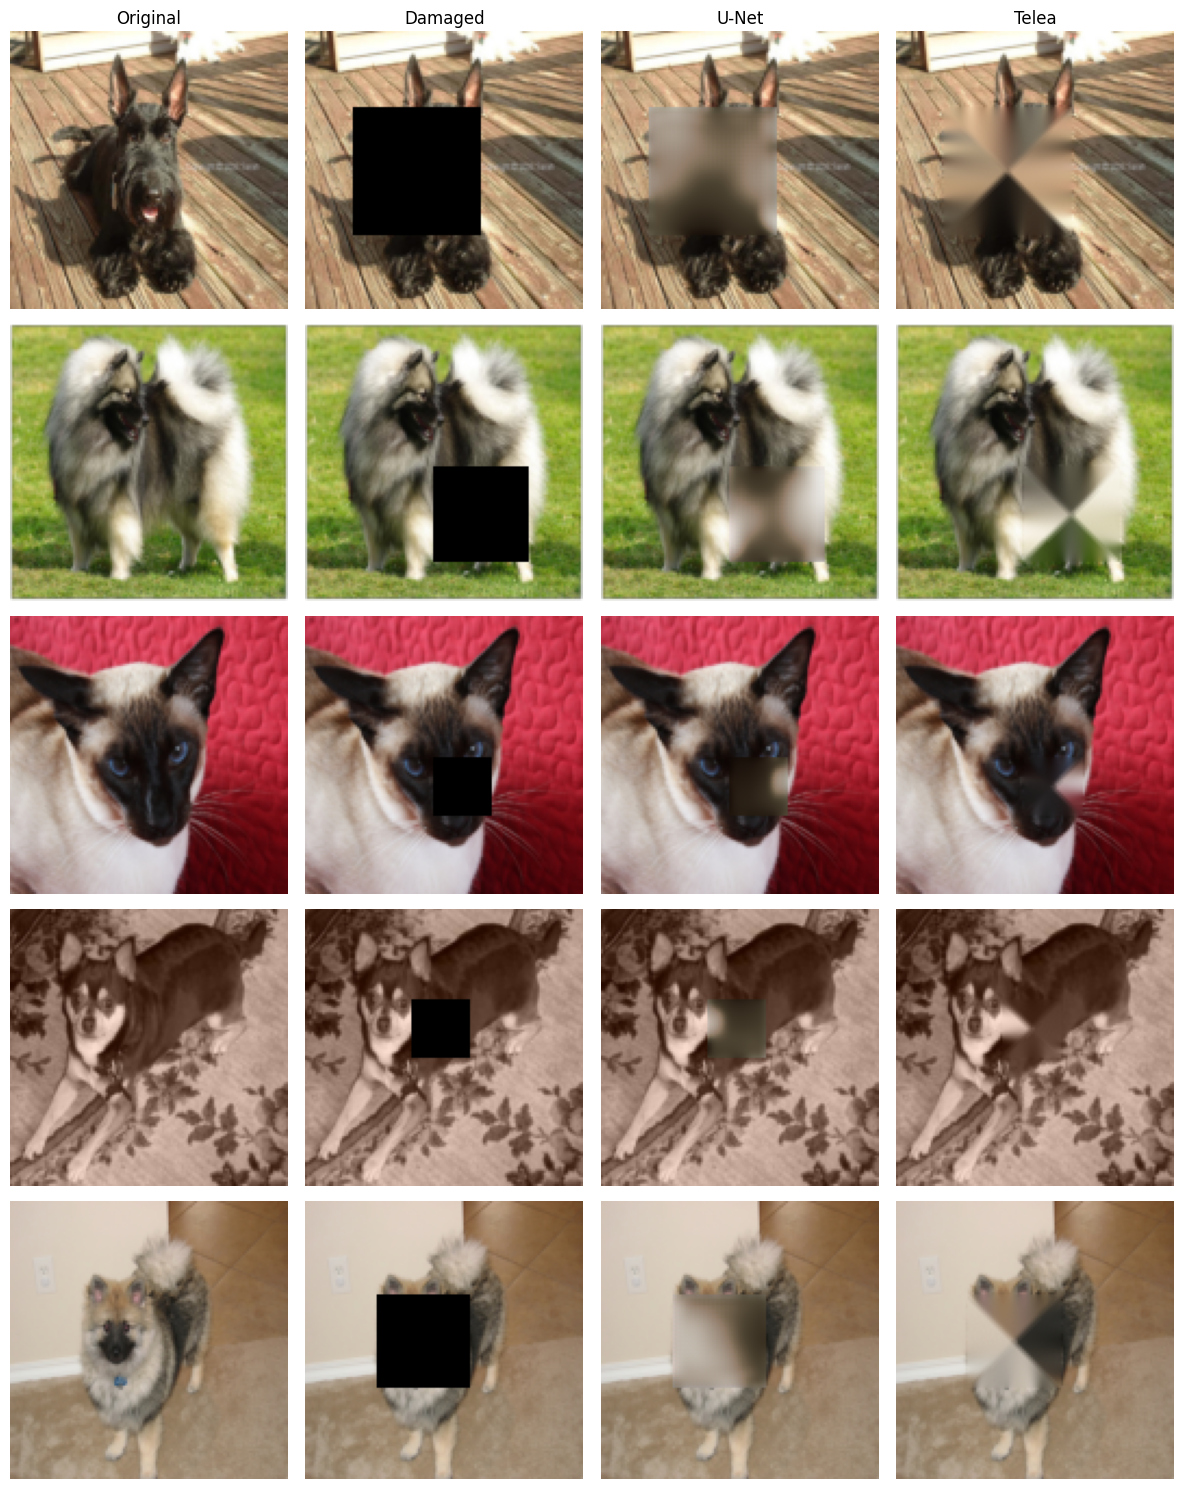


 U-Net largest losses


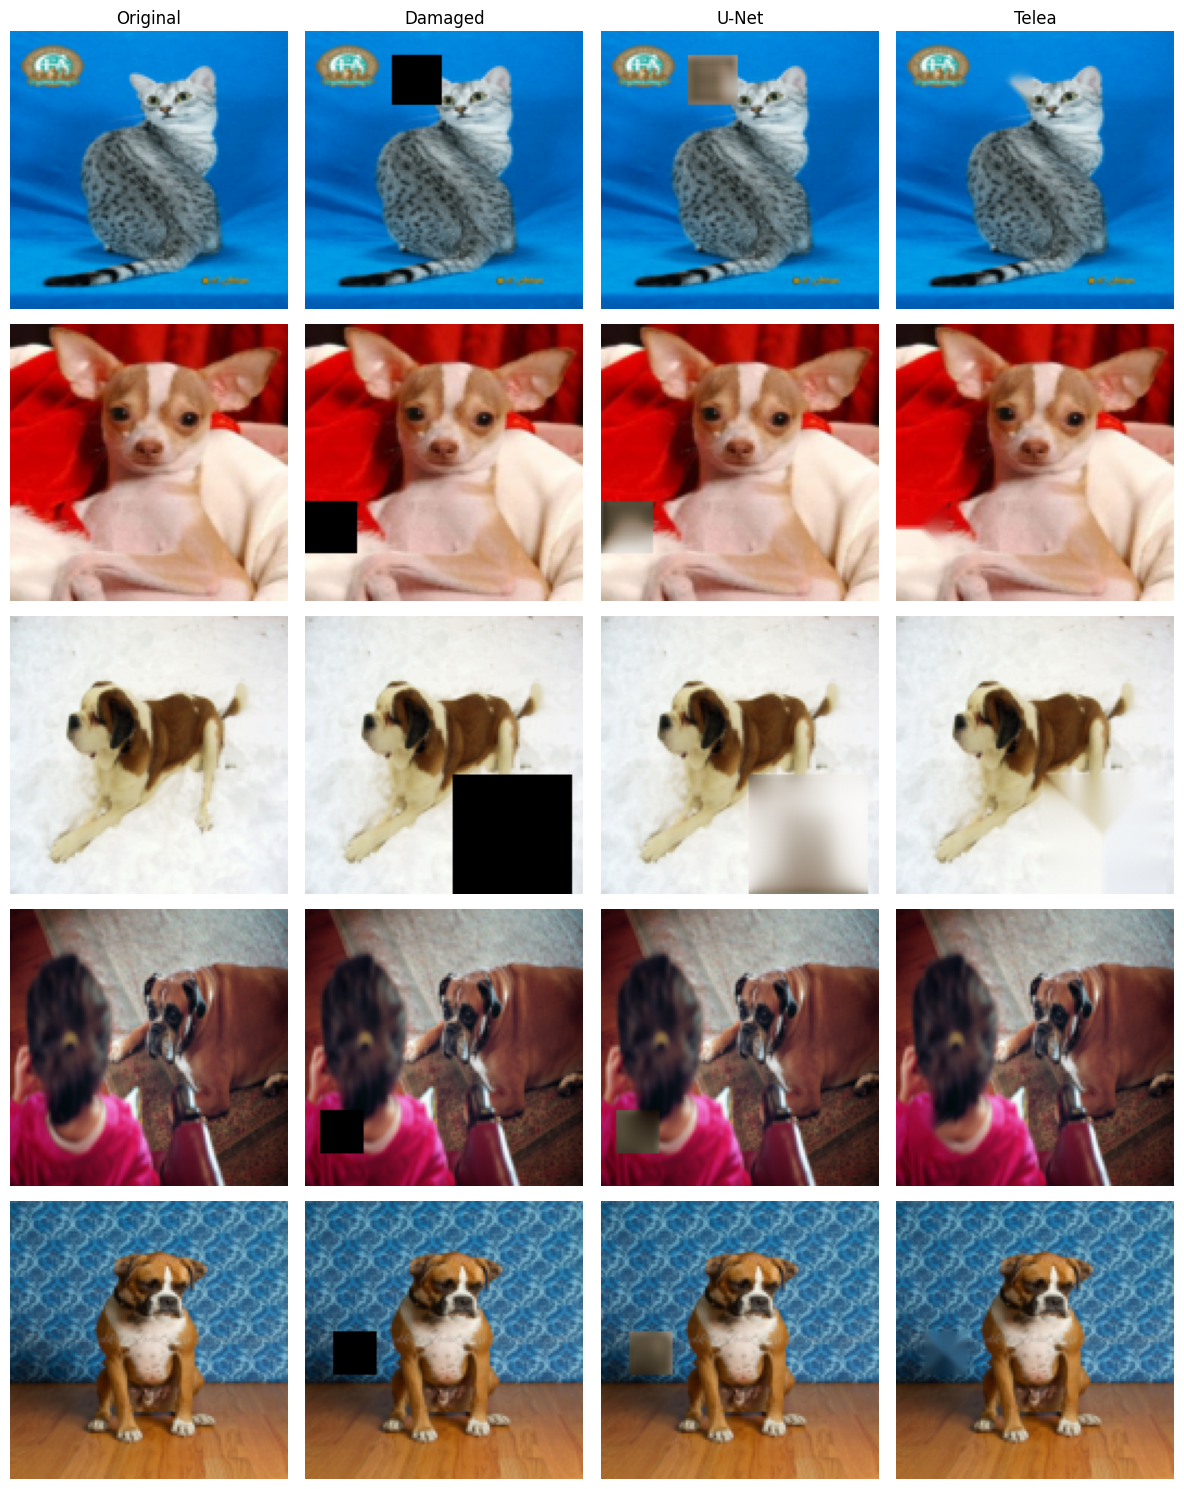

In [28]:

import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# Load improved model
checkpoint = torch.load(
    os.path.join(project_dir, "unet_improved.pth"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

# Recreate masks in validation order
torch.manual_seed(42)

saved_examples = {}

# Examine the five strongest U-Net wins
# plus five of its largest losses
best_ids = comparison.nsmallest(
    5, "improved_vs_telea"
)["image_id"].tolist()

worst_ids = comparison.nlargest(
    5, "improved_vs_telea"
)["image_id"].tolist()

selected_ids = set(best_ids + worst_ids)

image_counter = 0

with torch.no_grad():
    for images, _ in val_loader:
        masks = create_random_masks(images)

        damaged = images * (1 - masks)
        inputs = torch.cat([damaged, masks], dim=1)
        predictions = model(inputs)
        unet_restored = damaged + predictions * masks

        for i in range(len(images)):
            idx = image_counter + i

            if idx not in selected_ids:
                continue

            original = images[i]
            mask = masks[i]

            original_np = (
                original.permute(1, 2, 0).numpy() * 255
            ).round().astype(np.uint8)

            mask_np = (
                mask[0].numpy() * 255
            ).astype(np.uint8)

            damaged_np = original_np.copy()
            damaged_np[mask_np > 0] = 0

            telea_bgr = cv2.inpaint(
                cv2.cvtColor(
                    damaged_np, cv2.COLOR_RGB2BGR
                ),
                mask_np,
                3,
                cv2.INPAINT_TELEA
            )

            telea_rgb = cv2.cvtColor(
                telea_bgr, cv2.COLOR_BGR2RGB
            )

            saved_examples[idx] = [
                original.permute(1, 2, 0).numpy(),
                damaged[i].permute(1, 2, 0).numpy(),
                unet_restored[i].permute(1, 2, 0).numpy(),
                telea_rgb.astype(np.float32) / 255
            ]

        image_counter += len(images)

# Display comparison
for group_name, ids in [
    ("U-Net strongest wins", best_ids),
    ("U-Net largest losses", worst_ids)
]:
    print("\n", group_name)

    fig, axes = plt.subplots(
        len(ids), 4,
        figsize=(12, 3 * len(ids))
    )

    for row, idx in enumerate(ids):
        images_to_show = saved_examples[idx]

        for col, img in enumerate(images_to_show):
            axes[row, col].imshow(img)
            axes[row, col].axis("off")

            if row == 0:
                axes[row, col].set_title(
                    ["Original", "Damaged",
                     "U-Net", "Telea"][col]
                )

        axes[row, 0].set_ylabel(
            f"Image {idx}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()


In [29]:

import torch
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import os

# Load the improved model from Google Drive
checkpoint = torch.load(
    os.path.join(project_dir, "unet_improved.pth"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

mask_sizes = [20, 40, 60, 80]
records = []

# Fixed random positions, reproducible across runs
rng = np.random.default_rng(42)

# Evaluate on 100 validation images for this experiment
num_images = min(100, len(val_dataset))

with torch.no_grad():
    for image_id in range(num_images):

        original, _ = val_dataset[image_id]
        _, H, W = original.shape

        # Same relative mask center for every size
        # so only the square size changes
        center_x = int(rng.integers(40, W - 40))
        center_y = int(rng.integers(40, H - 40))

        original_np = (
            original.permute(1, 2, 0).numpy() * 255
        ).round().astype(np.uint8)

        for size in mask_sizes:

            x1 = center_x - size // 2
            y1 = center_y - size // 2

            mask = torch.zeros(1, H, W)
            mask[:, y1:y1+size, x1:x1+size] = 1

            damaged = original * (1 - mask)

            # U-Net prediction
            inputs = torch.cat(
                [damaged, mask], dim=0
            ).unsqueeze(0)

            prediction = model(inputs)[0]
            restored_unet = (
                damaged + prediction * mask
            )

            # OpenCV input
            mask_np = (
                mask[0].numpy() * 255
            ).astype(np.uint8)

            damaged_np = original_np.copy()
            damaged_np[mask_np > 0] = 0

            damaged_bgr = cv2.cvtColor(
                damaged_np, cv2.COLOR_RGB2BGR
            )

            scores = {
                "U-Net": calculate_mae(
                    original, restored_unet, mask
                )
            }

            for method, flag in [
                ("Telea", cv2.INPAINT_TELEA),
                ("Navier-Stokes", cv2.INPAINT_NS)
            ]:

                restored_bgr = cv2.inpaint(
                    damaged_bgr, mask_np, 3, flag
                )

                restored_rgb = cv2.cvtColor(
                    restored_bgr, cv2.COLOR_BGR2RGB
                )

                restored_tensor = torch.from_numpy(
                    restored_rgb.astype(np.float32) / 255
                ).permute(2, 0, 1)

                scores[method] = calculate_mae(
                    original, restored_tensor, mask
                )

            for method, score in scores.items():
                records.append({
                    "image_id": image_id,
                    "mask_size": size,
                    "method": method,
                    "masked_mae": score
                })

    print("Evaluation complete!")

results_df = pd.DataFrame(records)

summary = (
    results_df
    .groupby(["mask_size", "method"])["masked_mae"]
    .agg(["mean", "std"])
    .reset_index()
)

print(summary.to_string(index=False))

# Save raw and summarized results
results_df.to_csv(
    os.path.join(project_dir, "mask_size_detailed.csv"),
    index=False
)

summary.to_csv(
    os.path.join(project_dir, "mask_size_summary.csv"),
    index=False
)

print("\nResults saved to Google Drive!")


Evaluation complete!
 mask_size        method     mean      std
        20 Navier-Stokes 0.088091 0.038890
        20         Telea 0.087105 0.037835
        20         U-Net 0.108426 0.042968
        40 Navier-Stokes 0.114480 0.041310
        40         Telea 0.112202 0.039695
        40         U-Net 0.127230 0.037759
        60 Navier-Stokes 0.140172 0.045046
        60         Telea 0.136856 0.043572
        60         U-Net 0.147616 0.040108
        80 Navier-Stokes 0.146082 0.045195
        80         Telea 0.143347 0.044945
        80         U-Net 0.151534 0.039521

Results saved to Google Drive!


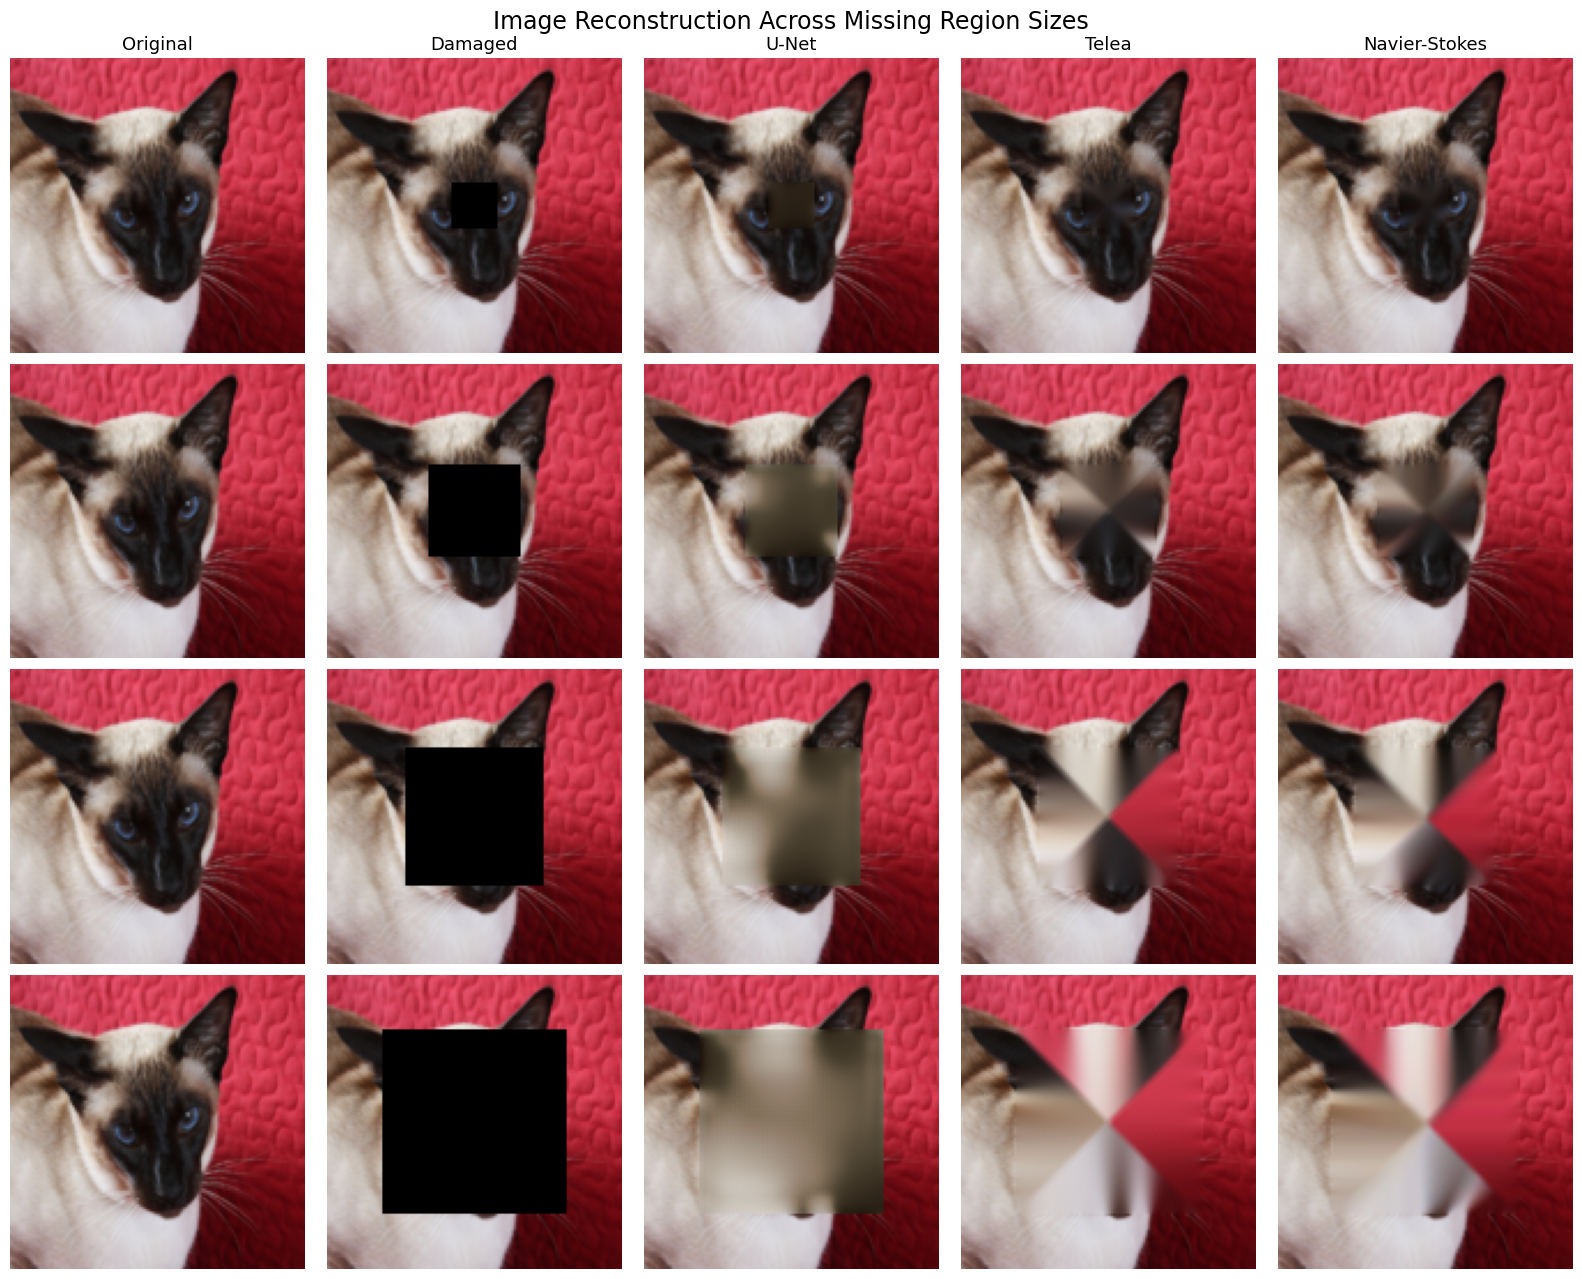

Figure saved to Google Drive!
Location: /content/drive/MyDrive/image_reconstruction/reconstruction_visual_comparison.png


In [30]:

import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import os

# Load our improved U-Net
checkpoint = torch.load(
    os.path.join(project_dir, "unet_improved.pth"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

# Choose one validation image
image_id = 14
original, _ = val_dataset[image_id]

C, H, W = original.shape
mask_sizes = [20, 40, 60, 80]

# Center the mask on the image
center_x = W // 2
center_y = H // 2

original_np = (
    original.permute(1, 2, 0).numpy() * 255
).round().astype(np.uint8)

fig, axes = plt.subplots(
    4, 5, figsize=(16, 13)
)

column_names = [
    "Original",
    "Damaged",
    "U-Net",
    "Telea",
    "Navier-Stokes"
]

for row, size in enumerate(mask_sizes):

    # Construct a centered square mask
    mask = torch.zeros(1, H, W)

    x1 = center_x - size // 2
    y1 = center_y - size // 2

    mask[:, y1:y1+size, x1:x1+size] = 1

    damaged = original * (1 - mask)

    # Neural network reconstruction
    inputs = torch.cat(
        [damaged, mask], dim=0
    ).unsqueeze(0)

    with torch.no_grad():
        prediction = model(inputs)[0]

    restored_unet = damaged + prediction * mask

    mask_np = (
        mask[0].numpy() * 255
    ).astype(np.uint8)

    damaged_np = original_np.copy()
    damaged_np[mask_np > 0] = 0

    damaged_bgr = cv2.cvtColor(
        damaged_np, cv2.COLOR_RGB2BGR
    )

    reconstructed = []

    for flag in [
        cv2.INPAINT_TELEA,
        cv2.INPAINT_NS
    ]:
        result_bgr = cv2.inpaint(
            damaged_bgr, mask_np, 3, flag
        )

        result_rgb = cv2.cvtColor(
            result_bgr, cv2.COLOR_BGR2RGB
        )

        reconstructed.append(
            result_rgb.astype(np.float32) / 255
        )

    display_images = [
        original.permute(1, 2, 0).numpy(),
        damaged.permute(1, 2, 0).numpy(),
        restored_unet.permute(1, 2, 0).numpy(),
        reconstructed[0],
        reconstructed[1]
    ]

    for col, img in enumerate(display_images):
        axes[row, col].imshow(
            np.clip(img, 0, 1)
        )
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(
                column_names[col],
                fontsize=13
            )

    axes[row, 0].set_ylabel(
        f"{size} px",
        fontsize=12
    )

plt.suptitle(
    "Image Reconstruction Across Missing Region Sizes",
    fontsize=17
)

plt.tight_layout()

figure_path = os.path.join(
    project_dir, "reconstruction_visual_comparison.png"
)

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to Google Drive!")
print("Location:", figure_path)


In [31]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

test_dataset = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",
    download=True,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Test images:", len(test_dataset))


Test images: 3669


In [32]:

import torch
import os

checkpoint = torch.load(
    os.path.join(project_dir, "unet_improved.pth"),
    map_location="cpu",
    weights_only=True
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to("cpu")
model.eval()

for parameter in model.parameters():
    parameter.requires_grad_(False)

print("Final U-Net checkpoint loaded and frozen.")


Final U-Net checkpoint loaded and frozen.


In [33]:

import torch
import numpy as np
import cv2
import pandas as pd
import os

torch.manual_seed(2026)

model.eval()
results = []

save_path = os.path.join(
    project_dir, "final_test_detailed.csv"
)

processed = 0

with torch.no_grad():
    for images, _ in test_loader:

        images = images.to("cpu")
        masks = create_random_masks(images)

        damaged = images * (1 - masks)
        inputs = torch.cat([damaged, masks], dim=1)

        predictions = model(inputs)
        restored_unet = damaged + predictions * masks

        for i in range(len(images)):
            original = images[i]
            mask = masks[i]

            scores = {
                "image_id": processed,
                "unet_mae": calculate_mae(
                    original, restored_unet[i], mask
                )
            }

            original_np = (
                original.permute(1, 2, 0).numpy() * 255
            ).round().astype(np.uint8)

            mask_np = (
                mask[0].numpy() * 255
            ).astype(np.uint8)

            damaged_np = original_np.copy()
            damaged_np[mask_np > 0] = 0

            damaged_bgr = cv2.cvtColor(
                damaged_np, cv2.COLOR_RGB2BGR
            )

            for name, flag in [
                ("telea_mae", cv2.INPAINT_TELEA),
                ("navier_stokes_mae", cv2.INPAINT_NS)
            ]:
                restored_bgr = cv2.inpaint(
                    damaged_bgr, mask_np, 3, flag
                )

                restored_rgb = cv2.cvtColor(
                    restored_bgr, cv2.COLOR_BGR2RGB
                )

                restored_tensor = torch.from_numpy(
                    restored_rgb.astype(np.float32) / 255
                ).permute(2, 0, 1)

                scores[name] = calculate_mae(
                    original, restored_tensor, mask
                )

            results.append(scores)
            processed += 1

        # Save periodically
        if processed % 200 < len(images):
            pd.DataFrame(results).to_csv(
                save_path, index=False
            )
            print(
                f"Processed {processed}/{len(test_dataset)} images"
            )

# Final save
final_results = pd.DataFrame(results)
final_results.to_csv(save_path, index=False)

print("\nFinal test evaluation completed!")
print("Total images evaluated:", len(final_results))
print("Results saved to:", save_path)


Processed 208/3669 images
Processed 400/3669 images
Processed 608/3669 images
Processed 800/3669 images
Processed 1008/3669 images
Processed 1200/3669 images
Processed 1408/3669 images
Processed 1600/3669 images
Processed 1808/3669 images
Processed 2000/3669 images
Processed 2208/3669 images
Processed 2400/3669 images
Processed 2608/3669 images
Processed 2800/3669 images
Processed 3008/3669 images
Processed 3200/3669 images
Processed 3408/3669 images
Processed 3600/3669 images

Final test evaluation completed!
Total images evaluated: 3669
Results saved to: /content/drive/MyDrive/image_reconstruction/final_test_detailed.csv


In [34]:

import pandas as pd
import numpy as np
import os

final_results = pd.read_csv(
    os.path.join(project_dir, "final_test_detailed.csv")
)

methods = {
    "U-Net": "unet_mae",
    "Telea": "telea_mae",
    "Navier-Stokes": "navier_stokes_mae"
}

final_summary = pd.DataFrame([
    {
        "Method": name,
        "Mean masked MAE": final_results[col].mean(),
        "Std Dev": final_results[col].std()
    }
    for name, col in methods.items()
])

final_summary = final_summary.sort_values(
    "Mean masked MAE"
)

print(final_summary.to_string(index=False))

final_summary.to_csv(
    os.path.join(project_dir, "final_test_summary.csv"),
    index=False
)

print("\nFinal summary saved!")


       Method  Mean masked MAE  Std Dev
        Telea         0.104550 0.047080
Navier-Stokes         0.105862 0.047653
        U-Net         0.122866 0.046257

Final summary saved!


In [35]:

import os
import json
import shutil

project_dir = "/content/drive/MyDrive/image_reconstruction"

folders = ["models", "results", "figures"]

for folder in folders:
    os.makedirs(
        os.path.join(project_dir, folder),
        exist_ok=True
    )

file_groups = {
    "models": [
        "unet_baseline_3epochs.pth",
        "unet_improved.pth",
        "unet_checkpoint.pth"
    ],
    "results": [
        "validation_benchmark.csv",
        "validation_detailed_results.csv",
        "model_improvement_comparison.csv",
        "mask_size_detailed.csv",
        "mask_size_summary.csv",
        "final_test_detailed.csv",
        "final_test_summary.csv"
    ],
    "figures": [
        "mask_size_comparison.png",
        "reconstruction_visual_comparison.png"
    ]
}

for folder, filenames in file_groups.items():
    for filename in filenames:
        source = os.path.join(project_dir, filename)
        destination = os.path.join(
            project_dir, folder, filename
        )

        if os.path.isfile(source):
            shutil.copy2(source, destination)
            print("Organized:", filename)
        else:
            print("Not found:", filename)

print("\nProject folders organized!")


Organized: unet_baseline_3epochs.pth
Organized: unet_improved.pth
Organized: unet_checkpoint.pth
Organized: validation_benchmark.csv
Organized: validation_detailed_results.csv
Organized: model_improvement_comparison.csv
Organized: mask_size_detailed.csv
Organized: mask_size_summary.csv
Organized: final_test_detailed.csv
Organized: final_test_summary.csv
Not found: mask_size_comparison.png
Organized: reconstruction_visual_comparison.png

Project folders organized!


In [36]:

config = {
    "project": "Beyond the Missing Pixels",
    "dataset": "Oxford-IIIT Pet",
    "image_resolution": [128, 128],
    "training_images": 3312,
    "validation_images": 368,
    "test_images": 3669,
    "models": [
        "Small U-Net",
        "Telea",
        "Navier-Stokes"
    ],
    "metric": "Masked Mean Absolute Error",
    "training": {
        "baseline": "3 epochs on 500 images",
        "improvement": "1 additional epoch on 3312 images",
        "initial_learning_rate": 0.001,
        "improvement_learning_rate": 0.0003,
        "loss": "Masked L1"
    },
    "test": {
        "random_seed": 2026,
        "mask_size_range_pixels": [20, 60],
        "unet_mae": 0.122866,
        "telea_mae": 0.104550,
        "navier_stokes_mae": 0.105862
    }
}

config_path = os.path.join(
    project_dir, "experiment_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=2)

print("Research configuration saved!")


Research configuration saved!
